In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score)
import joblib
import os

In [18]:
train_df = pd.read_csv("../dataset/train.csv")
test_df = pd.read_csv("../dataset/test.csv")
sample_df = pd.read_csv("../dataset/sample_submission.csv")
print("Datasets loaded successfully!")

Datasets loaded successfully!


In [20]:
print("Training Dataset Shape:", train_df.shape)
print("\nFirst 5 Records:")
display(train_df.head())
print("\nDataset Information:")
train_df.info()
print("\nStatistical Summary:")
display(train_df.describe())

Training Dataset Shape: (22750, 9)

First 5 Records:


,Employee ID,Date of Joining,Gender,Company Type,WFH Setup Available,Designation,Resource Allocation,Mental Fatigue Score,Burn Rate
0,fffe32003000360033003200,2008-09-30,Female,Service,No,2.0,3.0,3.8,0.16
1,fffe3700360033003500,2008-11-30,Male,Service,Yes,1.0,2.0,5.0,0.36
2,fffe31003300320037003900,2008-03-10,Female,Product,Yes,2.0,NaN,5.8,0.49
3,fffe32003400380032003900,2008-11-03,Male,Service,Yes,1.0,1.0,2.6,0.20
4,fffe31003900340031003600,2008-07-24,Female,Service,No,3.0,7.0,6.9,0.52



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22750 entries, 0 to 22749
Data columns (total 9 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Employee ID           22750 non-null  object 
 1   Date of Joining       22750 non-null  object 
 2   Gender                22750 non-null  object 
 3   Company Type          22750 non-null  object 
 4   WFH Setup Available   22750 non-null  object 
 5   Designation           22750 non-null  float64
 6   Resource Allocation   21369 non-null  float64
 7   Mental Fatigue Score  20633 non-null  float64
 8   Burn Rate             21626 non-null  float64
dtypes: float64(4), object(5)
memory usage: 1.6+ MB

Statistical Summary:


,Designation,Resource Allocation,Mental Fatigue Score,Burn Rate
count,22750.000000,21369.000000,20633.000000,21626.000000
mean,2.178725,4.481398,5.728188,0.452005
std,1.135145,2.047211,1.920839,0.198226
min,0.000000,1.000000,0.000000,0.000000
25%,1.000000,3.000000,4.600000,0.310000
50%,2.000000,4.000000,5.900000,0.450000
75%,3.000000,6.000000,7.100000,0.590000
max,5.000000,10.000000,10.000000,1.000000


In [21]:
print("Missing Values in Training Dataset:")
print(train_df.isnull().sum())
print("\nTotal Missing Values:")
print(train_df.isnull().sum().sum())

Missing Values in Training Dataset:
Employee ID                0
Date of Joining            0
Gender                     0
Company Type               0
WFH Setup Available        0
Designation                0
Resource Allocation     1381
Mental Fatigue Score    2117
Burn Rate               1124
dtype: int64

Total Missing Values:
4622


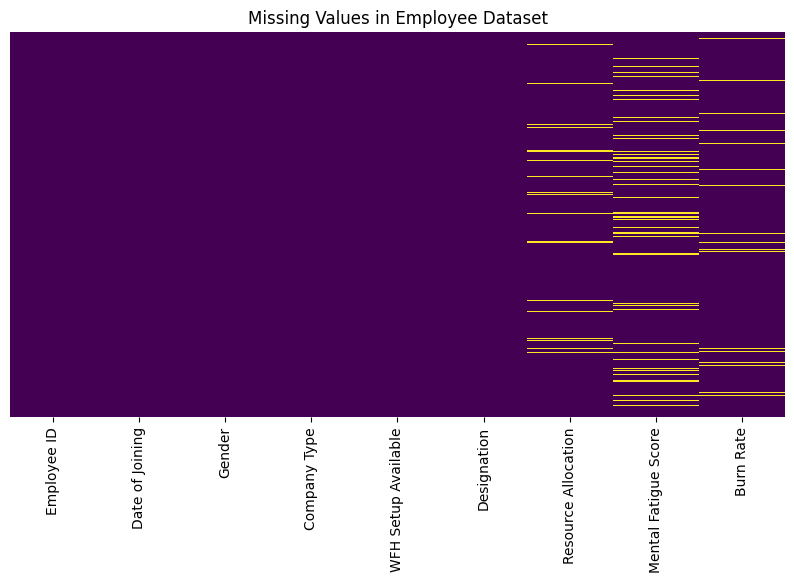

In [22]:
plt.figure(figsize=(10, 5))

sns.heatmap(
    train_df.isnull(),
    cbar=False,
    yticklabels=False,
    cmap="viridis"
)

plt.title("Missing Values in Employee Dataset")
plt.show()

In [23]:
print(train_df["Burn Rate"].describe())

count    21626.000000
mean         0.452005
std          0.198226
min          0.000000
25%          0.310000
50%          0.450000
75%          0.590000
max          1.000000
Name: Burn Rate, dtype: float64


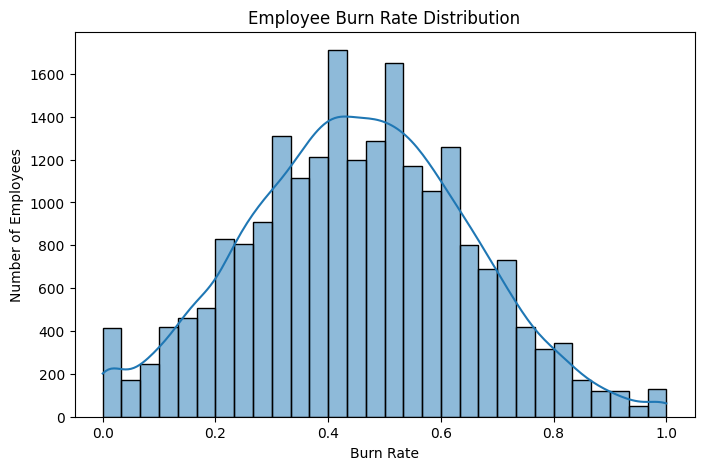

In [24]:
plt.figure(figsize=(8, 5))

sns.histplot(
    train_df["Burn Rate"].dropna(),
    bins=30,
    kde=True
)

plt.title("Employee Burn Rate Distribution")
plt.xlabel("Burn Rate")
plt.ylabel("Number of Employees")

plt.show()

In [25]:
train_df = train_df.dropna(subset=["Burn Rate"]).copy()
print("Training Dataset After Removing Missing Targets:")
print(train_df.shape)

Training Dataset After Removing Missing Targets:
(21626, 9)


In [26]:
train_df["Date of Joining"] = pd.to_datetime(
    train_df["Date of Joining"],
    errors="coerce"
)

test_df["Date of Joining"] = pd.to_datetime(
    test_df["Date of Joining"],
    errors="coerce"
)

train_df["Joining Month"] = train_df["Date of Joining"].dt.month

test_df["Joining Month"] = test_df["Date of Joining"].dt.month

In [27]:
train_df.drop(
    columns=["Employee ID", "Date of Joining", "Gender"],
    inplace=True
)

test_ids = test_df["Employee ID"].copy()

test_df.drop(
    columns=["Employee ID", "Date of Joining", "Gender"],
    inplace=True
)

print("Unnecessary columns removed!")

Unnecessary columns removed!


In [28]:
X = train_df.drop(columns=["Burn Rate"])

y = train_df["Burn Rate"]

print("Input Shape:", X.shape)

print("Output Shape:", y.shape)

print("\nInput Columns:")
print(X.columns.tolist())

Input Shape: (21626, 6)
Output Shape: (21626,)

Input Columns:
['Company Type', 'WFH Setup Available', 'Designation', 'Resource Allocation', 'Mental Fatigue Score', 'Joining Month']


In [29]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training Records:", X_train.shape[0])

print("Testing Records:", X_test.shape[0])

Training Records: 17300
Testing Records: 4326


In [30]:
numeric_features = [
    "Designation",
    "Resource Allocation",
    "Mental Fatigue Score",
    "Joining Month"
]

categorical_features = [
    "Company Type",
    "WFH Setup Available"
]